# Fermate del trasporto pubblico locale di Milano: risultati

Analisi dei dati mostrati nella dashboard (`index.html`), con i dataset aperti del Comune di Milano / ATM (licenza CC BY) già presenti nella cartella `data/`:

1. **Dati**: fermate di superficie e stazioni della metropolitana.
2. **Linee**: quante fermate ha ogni linea.
3. **Fermate**: quante linee servono ogni fermata, e quali sono i nodi principali.
4. **Metropolitana**: stazioni per linea e interscambi.
5. **Territorio**: fermate e densità per Municipio, fermate fuori dal Comune.
6. **Copertura della metropolitana**: distanza delle fermate di superficie dalla stazione più vicina.

Il notebook usa solo pandas, NumPy e Matplotlib e non richiede connessione a Internet.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.path import Path as Percorso

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
pd.set_option("display.float_format", "{:,.1f}".format)
plt.rcParams["figure.dpi"] = 90
BLU, VERDE = "#2f6db5", "#5a8f29"
COLORI_METRO = {"M1": "#e3001b", "M2": "#00a650", "M3": "#f9b000", "M4": "#0075bf", "M5": "#9b4f96"}

fonte = json.loads((DATA / "fonte.json").read_text(encoding="utf-8"))
geojson = json.loads((DATA / "fermate.geojson").read_text(encoding="utf-8"))
municipi = json.loads((DATA / "municipi.geojson").read_text(encoding="utf-8"))["features"]

righe = []
for f in geojson["features"]:
    p = f["properties"]
    lon, lat = f["geometry"]["coordinates"]
    # Le linee metro hanno codici 1-5 come alcuni tram: si distinguono con il prefisso M
    linee = ["M" + l for l in p["linee"]] if p["tipo"] == "metro" else p["linee"]
    righe.append({"id": p["id"], "nome": p["nome"], "tipo": p["tipo"], "linee": linee, "lon": lon, "lat": lat})
fermate = pd.DataFrame(righe)
fermate["n_linee"] = fermate["linee"].str.len()
superficie = fermate[fermate["tipo"] == "superficie"].copy()
metro = fermate[fermate["tipo"] == "metro"].copy()
fermate.head()

,id,nome,tipo,linee,lon,lat,n_linee
0,10000,Cherasco,superficie,[161],9.2,45.5,1
1,10003,"Via Bovisasca, 18 dopo Via C.Battisti",superficie,[89],9.1,45.5,1
2,10008,"Via Bovisasca, 15/A prima di Via Baracca",superficie,[89],9.1,45.5,1
3,10018,"C.so Sempione, 83 prima di Via E. Filiberto",superficie,[48],9.2,45.5,1
4,10021,Viale Alfa Romeo fronte civico 17,superficie,[561],9.1,45.6,1


## 1. Dati

In [2]:
pd.DataFrame({
    nome: {"dataset": d["dataset"], "aggiornato sul portale": d["aggiornato_sul_portale"], "licenza": d["licenza"],
           "record": d.get("fermate", d.get("municipi"))}
    for nome, d in fonte["dataset"].items()
}).T

,dataset,aggiornato sul portale,licenza,record
superficie,ATM - Fermate linee di superficie urbane,2026-07-24,Creative Commons Attribution,4683
metro,ATM - Fermate linee metropolitane,2026-07-24,Creative Commons Attribution,130
municipi,Territorio: superficie dei Municipi,2026-05-08,Creative Commons Attribution,9


In [3]:
pd.DataFrame({
    "fermate": fermate.groupby("tipo").size(),
    "linee": fermate.explode("linee").groupby("tipo")["linee"].nunique(),
})

,fermate,linee
tipo,,
metro,130,5
superficie,4683,160


Il dataset delle fermate di superficie contiene 4.683 fermate di bus, tram e filobus servite da 160 linee; quello della metropolitana 130 stazioni delle 5 linee. Le fermate dei due sensi di marcia sono record distinti, con nomi diversi (per esempio "Via G.Grassi, 23" e "Via G.Grassi fronte 23"): i conteggi delle fermate per linea comprendono quindi entrambe le direzioni.

## 2. Linee: numero di fermate

In [4]:
per_linea = superficie.explode("linee").groupby("linee").size().sort_values(ascending=False)
per_linea.describe().to_frame("fermate per linea").T

,count,mean,std,min,25%,50%,75%,max
fermate per linea,160.0,43.8,23.1,1.0,30.0,45.0,59.0,117.0


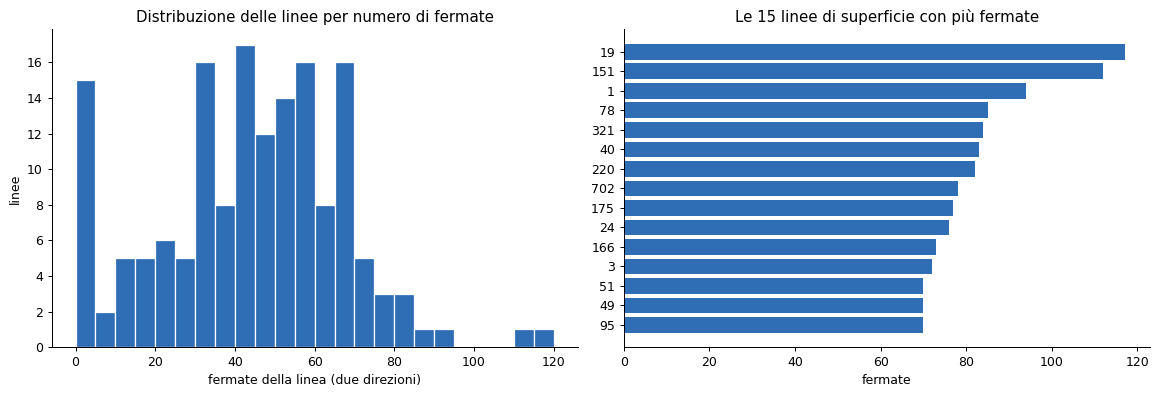

In [5]:
fig, (sinistra, destra) = plt.subplots(1, 2, figsize=(13, 4.5))
sinistra.hist(per_linea, bins=range(0, 125, 5), color=BLU, edgecolor="white")
sinistra.set_xlabel("fermate della linea (due direzioni)")
sinistra.set_ylabel("linee")
sinistra.set_title("Distribuzione delle linee per numero di fermate")
prime = per_linea.head(15)[::-1]
destra.barh(prime.index, prime.values, color=BLU)
destra.set_xlabel("fermate")
destra.set_title("Le 15 linee di superficie con più fermate")
for asse in (sinistra, destra):
    asse.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [6]:
# Linee con meno di 5 fermate
per_linea[per_linea < 5].to_frame("fermate").T

linee,1034,1078,183,1088,1044,1046,1039,1079,1086,1075,1076,1055,1052,1045,1035
fermate,4,4,4,3,3,2,2,2,2,2,2,2,2,1,1


In mediana una linea di superficie ha 45 fermate, contando le due direzioni. Il tram 19 (117) e il bus 151 (112) sono le linee con più fermate. All'estremo opposto 15 linee hanno meno di 5 fermate: sono quasi tutte linee con codici a quattro cifre (1034, 1078…), di cui il dataset riporta solo poche fermate, più la linea 183 con 4 fermate.

## 3. Fermate: numero di linee e nodi principali

In [7]:
distribuzione = fermate["n_linee"].value_counts().sort_index()
pd.DataFrame({"fermate": distribuzione, "quota": distribuzione / distribuzione.sum() * 100})

,fermate,quota
n_linee,,
1,3120,64.8
2,1236,25.7
3,333,6.9
4,89,1.8
5,23,0.5
6,10,0.2
7,1,0.0
8,1,0.0


In [8]:
superficie.nlargest(10, "n_linee")[["nome", "n_linee", "linee"]].assign(linee=lambda d: d["linee"].str.join(", "))

,nome,n_linee,linee
2450,Via Comasina dopo Via Teano,8,"41, 52, 83, 89, 153, 165, 705, 729"
2084,"P.za Bottini, 10 - Stz Lambrate",7,"19, 39, 45, 54, 152, 175, 924"
979,"C.so Colombo, 5 prima di V.le Gorizia",6,"2, 3, 10, 74, 126, 152"
1291,"Via Ornato, 136",6,"40, 52, 83, 161, 166, 708"
1376,"Via V. di Modrone, 18 prima di Via Mascagni",6,"61, 84, 97, 151, 153, 154"
1468,Via F.Filzi prima di Via Tonale,6,"5, 10, 42, 87, 153, 728"
2033,V.le Corsica dopo Via De Andreis,6,"24, 45, 127, 154, 175, 973"
2180,V.le Ungheria dopo L.go Guerrieri Gonzaga,6,"24, 45, 66, 88, 127, 175"
3149,Via Bauer dopo Via Passerini,6,"42, 51, 83, 161, 166, 172"
3279,Via Danzi dopo Via Racconigi,6,"41, 51, 83, 161, 166, 172"


Due fermate su tre (65%) sono servite da una sola linea e solo 124 (2,6%) da 4 o più. Il nodo di superficie con più linee è "Via Comasina dopo Via Teano" (8 linee), seguito dalla fermata di Piazza Bottini davanti alla stazione di Lambrate (7).

## 4. Metropolitana

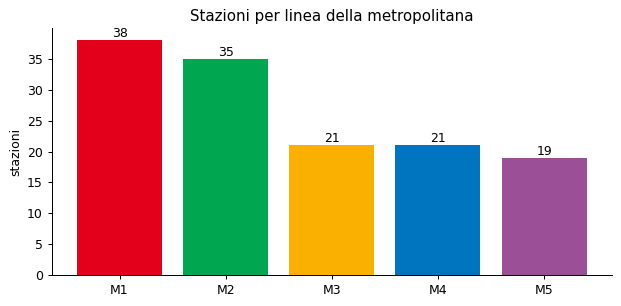

In [9]:
stazioni_per_linea = metro.explode("linee").groupby("linee").size()
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(stazioni_per_linea.index, stazioni_per_linea.values, color=[COLORI_METRO[l] for l in stazioni_per_linea.index])
for i, v in enumerate(stazioni_per_linea.values):
    ax.text(i, v + 0.5, str(v), ha="center")
ax.set_ylabel("stazioni")
ax.set_title("Stazioni per linea della metropolitana")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Nei dati solo 4 stazioni di interscambio sono un unico record con più linee. Le altre compaiono come record separati, uno per linea e con nomi diversi (per esempio "DUOMO M1" e "DUOMO M3"). Per contarle si uniscono le stazioni di linee diverse distanti meno di 250 metri:

In [10]:
def distanze(a, b):
    """Distanze in metri tra due insiemi di punti (lon, lat), con la formula dell'emisenoverso."""
    la1, lo1 = np.radians(a[:, 1])[:, None], np.radians(a[:, 0])[:, None]
    la2, lo2 = np.radians(b[:, 1])[None], np.radians(b[:, 0])[None]
    h = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return 2 * 6_371_000 * np.arcsin(np.sqrt(h))


m = metro.reset_index(drop=True)
d = distanze(m[["lon", "lat"]].to_numpy(), m[["lon", "lat"]].to_numpy())
interscambi = [{"stazione": r["nome"], "linee": " / ".join(r["linee"]), "distanza tra i record (m)": 0}
               for _, r in m[m["n_linee"] > 1].iterrows()]
for i in range(len(m)):
    for j in range(i + 1, len(m)):
        if d[i, j] < 250 and set(m["linee"][i]) != set(m["linee"][j]):
            interscambi.append({"stazione": f"{m['nome'][i]} + {m['nome'][j]}",
                                "linee": " / ".join(sorted(m["linee"][i] + m["linee"][j])),
                                "distanza tra i record (m)": round(d[i, j])})
interscambi = pd.DataFrame(interscambi)
print(f"Interscambi: {len(interscambi)}. Stazioni distinte: {len(m) - (len(interscambi) - (m['n_linee'] > 1).sum())}")
interscambi

Interscambi: 9. Stazioni distinte: 125


,stazione,linee,distanza tra i record (m)
0,ZARA,M3 / M5,0
1,SAN BABILA,M1 / M4,0
2,GARIBALDI FS,M2 / M5,0
3,CENTRALE FS,M2 / M3,0
4,SAN AMBROGIO + S.AMBROGIO,M2 / M4,22
5,LOTTO M5 + LOTTO FIERAMILANOCITY,M1 / M5,71
6,LORETO M2 + LORETO M1,M1 / M2,231
7,DUOMO M3 + DUOMO M1,M1 / M3,111
8,CADORNA FN M2 + CADORNA FN M1,M1 / M2,53


La rete ha 9 stazioni di interscambio, ognuna tra due linee, e 125 stazioni distinte: la somma delle stazioni per linea (134) meno i 9 interscambi. Le linee M1 e M2 sono le più estese (38 e 35 stazioni) e arrivano oltre il confine comunale. Delle 21 stazioni in altri comuni, 14 sono della M2 (Cologno Monzese, Assago e la diramazione verso Gessate), 6 della M1 (Sesto San Giovanni, Pero e Rho) e una della M4 (Linate Aeroporto).

## 5. Territorio: fermate per Municipio

Ogni fermata viene assegnata al Municipio che la contiene, con i confini ufficiali dei 9 Municipi (dataset ds379). Le fermate fuori da tutti i Municipi sono fuori dal Comune di Milano: sono le fermate delle linee urbane nei comuni dell'area urbana.

In [11]:
punti = fermate[["lon", "lat"]].to_numpy()
fermate["municipio"] = 0
superfici = {}
for m_ in municipi:
    anelli = m_["geometry"]["coordinates"]  # tutti i Municipi sono poligoni semplici, senza buchi
    dentro = Percorso(anelli[0]).contains_points(punti)
    fermate.loc[dentro, "municipio"] = m_["properties"]["municipio"]
    superfici[m_["properties"]["municipio"]] = m_["properties"]["superficie_km2"]
superficie["municipio"] = fermate.loc[superficie.index, "municipio"]
metro["municipio"] = fermate.loc[metro.index, "municipio"]

fuori = (superficie["municipio"] == 0).sum()
print(f"Fermate di superficie fuori dal Comune: {fuori:,} su {len(superficie):,} ({fuori / len(superficie):.0%})".replace(",", "."))
print(f"Stazioni della metropolitana fuori dal Comune: {(metro['municipio'] == 0).sum()}")

Fermate di superficie fuori dal Comune: 1.590 su 4.683 (34%)
Stazioni della metropolitana fuori dal Comune: 21


In [12]:
per_municipio = pd.DataFrame({
    "superficie (km²)": pd.Series(superfici),
    "fermate di superficie": superficie[superficie["municipio"] > 0].groupby("municipio").size(),
    "stazioni metro (record)": metro[metro["municipio"] > 0].groupby("municipio").size(),
}).fillna(0).rename_axis("municipio")
per_municipio["fermate per km²"] = per_municipio["fermate di superficie"] / per_municipio["superficie (km²)"]
totale = per_municipio.sum()
totale["fermate per km²"] = totale["fermate di superficie"] / totale["superficie (km²)"]
per_municipio.loc["Comune"] = totale
per_municipio

,superficie (km²),fermate di superficie,stazioni metro (record),fermate per km²
municipio,,,,
1,9.4,266.0,23.0,28.2
2,12.6,290.0,11.0,23.0
3,14.4,325.0,11.0,22.5
4,20.7,367.0,8.0,17.7
5,30.0,292.0,3.0,9.7
6,18.3,349.0,14.0,19.0
7,31.4,366.0,11.0,11.7
8,23.9,435.0,13.0,18.2
9,21.0,403.0,15.0,19.2


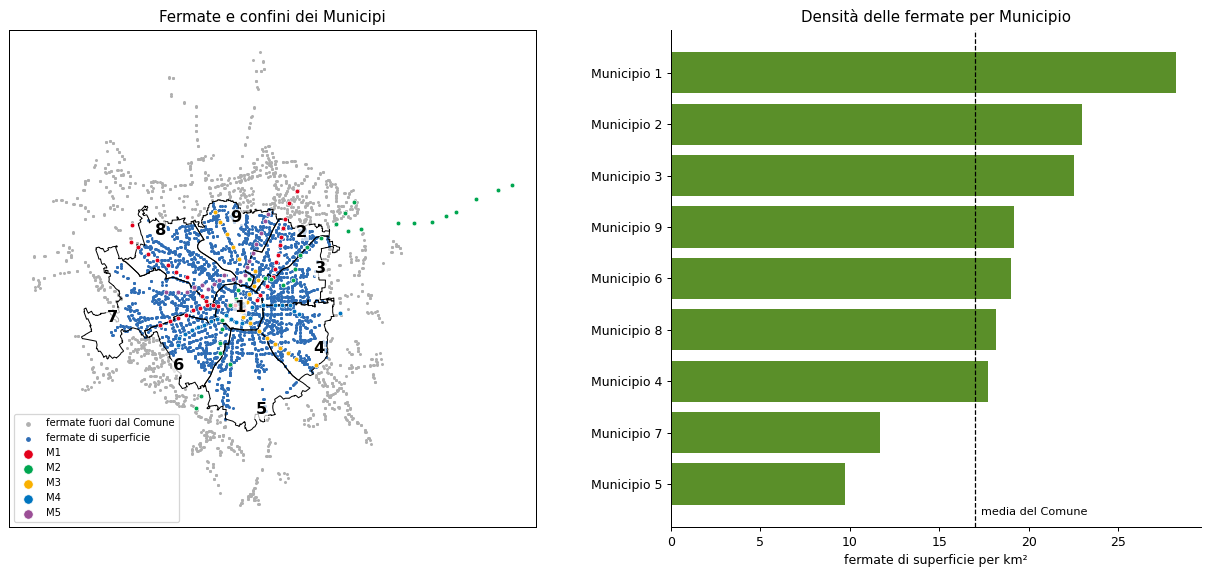

In [13]:
fig, (mappa, barre) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
dentro = superficie[superficie["municipio"] > 0]
fuori_comune = superficie[superficie["municipio"] == 0]
mappa.scatter(fuori_comune["lon"], fuori_comune["lat"], s=2, color="#b0b0b0", label="fermate fuori dal Comune")
mappa.scatter(dentro["lon"], dentro["lat"], s=2, color=BLU, label="fermate di superficie")
for linea, colore in COLORI_METRO.items():
    s = metro[metro["linee"].apply(lambda l: linea in l)]
    mappa.scatter(s["lon"], s["lat"], s=14, color=colore, edgecolor="white", linewidth=0.5, zorder=3, label=linea)
for m_ in municipi:
    anello = np.array(m_["geometry"]["coordinates"][0])
    mappa.plot(anello[:, 0], anello[:, 1], color="black", lw=0.8)
    cx, cy = anello.mean(axis=0)
    mappa.text(cx, cy, str(m_["properties"]["municipio"]), fontsize=13, weight="bold", ha="center", va="center",
               bbox={"facecolor": "white", "alpha": 0.7, "edgecolor": "none", "pad": 1})
mappa.set_aspect(1 / np.cos(np.radians(45.46)))
mappa.set_title("Fermate e confini dei Municipi")
mappa.legend(loc="lower left", fontsize=8, markerscale=2, frameon=True)
mappa.set_xticks([]); mappa.set_yticks([])

densita = per_municipio.drop("Comune")["fermate per km²"].sort_values()
barre.barh([f"Municipio {i}" for i in densita.index], densita.values, color=VERDE)
barre.axvline(per_municipio.loc["Comune", "fermate per km²"], color="black", ls="--", lw=1)
barre.text(per_municipio.loc["Comune", "fermate per km²"] + 0.3, -0.6, "media del Comune", fontsize=9)
barre.set_xlabel("fermate di superficie per km²")
barre.set_title("Densità delle fermate per Municipio")
barre.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

- Un terzo delle fermate di superficie (1.590 su 4.683, il 34%) è fuori dal Comune di Milano: la rete urbana serve anche i comuni dell'area urbana.
- Nel Comune ci sono in media 17 fermate di superficie per km². La densità è massima nel Municipio 1, il centro storico (28 per km²), e minima nel Municipio 5, a sud (meno di 10), che comprende vaste aree agricole del Parco Agricolo Sud.
- Il Municipio 1 ha anche il maggior numero di stazioni della metropolitana (23 record), il Municipio 5 il minore (3).

## 6. Copertura della metropolitana

Per ogni fermata di superficie si calcola la distanza in linea d'aria dalla stazione della metropolitana più vicina.

In [14]:
superficie["distanza_metro"] = distanze(superficie[["lon", "lat"]].to_numpy(), metro[["lon", "lat"]].to_numpy()).min(axis=1)
nel_comune = superficie[superficie["municipio"] > 0]
pd.DataFrame({
    "tutte le fermate": [(superficie["distanza_metro"] <= s).mean() * 100 for s in (300, 500, 1000)],
    "fermate nel Comune": [(nel_comune["distanza_metro"] <= s).mean() * 100 for s in (300, 500, 1000)],
}, index=["entro 300 m", "entro 500 m", "entro 1 km"]).rename_axis("% di fermate di superficie")

,tutte le fermate,fermate nel Comune
% di fermate di superficie,,
entro 300 m,19.9,28.4
entro 500 m,34.4,48.7
entro 1 km,55.6,76.5


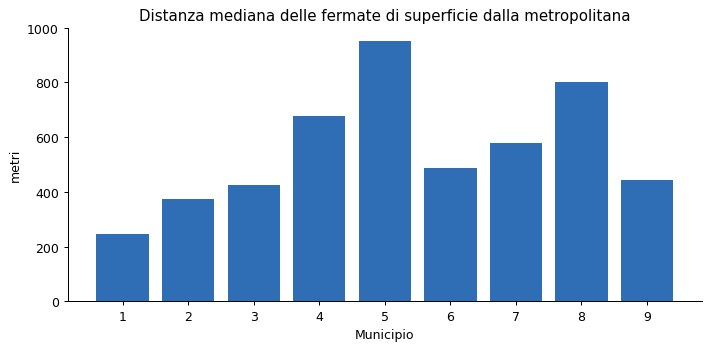

,distanza_mediana_m,quota_entro_500m
municipio,,
1,247.0,86.8
2,375.1,63.1
3,426.0,59.4
4,678.3,36.5
5,953.4,17.1
6,487.8,51.0
7,579.1,41.8
8,802.5,36.6
9,444.3,55.8


In [15]:
copertura = nel_comune.groupby("municipio").agg(
    distanza_mediana_m=("distanza_metro", "median"),
    quota_entro_500m=("distanza_metro", lambda d: (d <= 500).mean() * 100),
)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar([str(i) for i in copertura.index], copertura["distanza_mediana_m"], color=BLU)
ax.set_xlabel("Municipio")
ax.set_ylabel("metri")
ax.set_title("Distanza mediana delle fermate di superficie dalla metropolitana")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
copertura

- Nel Comune circa metà delle fermate di superficie (49%) è entro 500 metri in linea d'aria da una stazione della metropolitana, e tre su quattro (77%) entro un chilometro.
- La distanza cresce dal centro verso la periferia: la mediana è di circa 250 metri nel Municipio 1 e di circa 950 metri nel Municipio 5. Nelle zone più lontane dalla metropolitana bus e tram sono l'unico collegamento.
- Fuori dal Comune la distanza mediana supera i 2 km.

## Conclusioni
- La rete di superficie è capillare: 4.683 fermate e 160 linee. Ma la maggior parte delle fermate (65%) è servita da una sola linea, e i nodi con molte linee sono pochi.
- La metropolitana ha 125 stazioni distinte e 9 interscambi; nei dati alcuni interscambi sono record separati, di cui tenere conto nei conteggi.
- La copertura è disomogenea tra i Municipi: il centro ha più fermate e stazioni vicine, il Municipio 5 la densità più bassa e le fermate più lontane dalla metropolitana.
- Un'analisi più completa richiederebbe dati sulla popolazione per Municipio o per sezione di censimento, sulle frequenze delle corse e sull'accessibilità delle fermate, presenti nella prima versione del progetto ma non pubblicati come dati aperti.